# Agentic RAG with LangGraph
1. Load Wikipedia pages with `WebBaseLoader`
2. Split + embed into a **FAISS** vector store
3. Expose the retriever as a tool
4. LangGraph graph: **agent → (retrieve) → grade → generate / rewrite**

In [1]:
# !pip install faiss-cpu langchain-community langchain-groq langchain-huggingface sentence-transformers langgraph bs4

In [2]:
import os
from dotenv import load_dotenv
load_dotenv("../.env")

os.environ["USER_AGENT"] = "agentic-rag-demo"
os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY")
os.environ["HF_TOKEN"] = os.getenv("HF_TOKEN", "")

## 1. Load Wikipedia URLs

In [3]:
from langchain_community.document_loaders import WebBaseLoader
import bs4

urls = [
    "https://en.wikipedia.org/wiki/Retrieval-augmented_generation",
    "https://en.wikipedia.org/wiki/Large_language_model",
    "https://en.wikipedia.org/wiki/Vector_database",
]

loader = WebBaseLoader(
    web_paths=urls,
    bs_kwargs={"parse_only": bs4.SoupStrainer("div", attrs={"id": "mw-content-text"})},
)
docs = loader.load()
len(docs), docs[0].metadata

/var/folders/d0/tvnvw1q168902k33x22mkq340000gn/T/ipykernel_15475/3613027532.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import WebBaseLoader


(3, {'source': 'https://en.wikipedia.org/wiki/Retrieval-augmented_generation'})

## 2. Split and store in FAISS

In [4]:
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_community.vectorstores import FAISS

splitter = RecursiveCharacterTextSplitter(chunk_size=1000, chunk_overlap=150)
chunks = splitter.split_documents(docs)

embeddings = HuggingFaceEmbeddings(model_name="sentence-transformers/all-MiniLM-L6-v2")
vectorstore = FAISS.from_documents(chunks, embeddings)
retriever = vectorstore.as_retriever(search_kwargs={"k": 4})
len(chunks)

/Users/jobayerahmed/Documents/ML/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1031 20:30:46.748000 15475 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 5534.09it/s]


209

In [5]:
# optional: persist / reload
# vectorstore.save_local("faiss_wiki")
# vectorstore = FAISS.load_local("faiss_wiki", embeddings, allow_dangerous_deserialization=True)

## 3. Retriever tool + LLM

In [6]:
from langchain_core.tools import tool
from langchain_groq import ChatGroq

@tool
def wiki_retriever(query: str) -> str:
    """Search Wikipedia articles about RAG, large language models and vector databases."""
    results = retriever.invoke(query)
    return "\n\n".join(d.page_content for d in results)

tools = [wiki_retriever]
llm = ChatGroq(model="openai/gpt-oss-120b", temperature=0)

## 4. Graph nodes

In [7]:
from typing import Literal
from pydantic import BaseModel, Field
from langgraph.graph import MessagesState
from langchain_core.messages import HumanMessage

def agent(state: MessagesState):
    """Decide whether to call the retriever or answer directly."""
    response = llm.bind_tools(tools).invoke(state["messages"])
    return {"messages": [response]}


class Grade(BaseModel):
    binary_score: Literal["yes", "no"] = Field(description="Is the context relevant to the question?")

def grade_documents(state: MessagesState) -> Literal["generate", "rewrite"]:
    """Route to generate if retrieved context is relevant, else rewrite the question."""
    question = state["messages"][0].content
    context = state["messages"][-1].content
    grader = llm.with_structured_output(Grade)
    score = grader.invoke(
        f"Question: {question}\n\nRetrieved context:\n{context}\n\n"
        "Does the context contain information relevant to the question? Answer yes or no."
    )
    return "generate" if score.binary_score == "yes" else "rewrite"


def rewrite(state: MessagesState):
    """Reformulate the question for better retrieval."""
    question = state["messages"][0].content
    better = llm.invoke(
        f"Rewrite this question so it is clearer and better suited for searching Wikipedia. "
        f"Return only the rewritten question.\n\nQuestion: {question}"
    )
    return {"messages": [HumanMessage(content=better.content)]}


def generate(state: MessagesState):
    """Answer the question using the retrieved context."""
    question = state["messages"][0].content
    context = state["messages"][-1].content
    answer = llm.invoke(
        "You are an assistant for question answering. Use the context below to answer. "
        "If you don't know, say so. Keep it concise.\n\n"
        f"Question: {question}\n\nContext:\n{context}"
    )
    return {"messages": [answer]}

## 5. Build the graph

In [8]:
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode, tools_condition

builder = StateGraph(MessagesState)
builder.add_node("agent", agent)
builder.add_node("retrieve", ToolNode(tools))
builder.add_node("rewrite", rewrite)
builder.add_node("generate", generate)

builder.add_edge(START, "agent")
builder.add_conditional_edges("agent", tools_condition, {"tools": "retrieve", END: END})
builder.add_conditional_edges("retrieve", grade_documents)
builder.add_edge("rewrite", "agent")
builder.add_edge("generate", END)

graph = builder.compile()

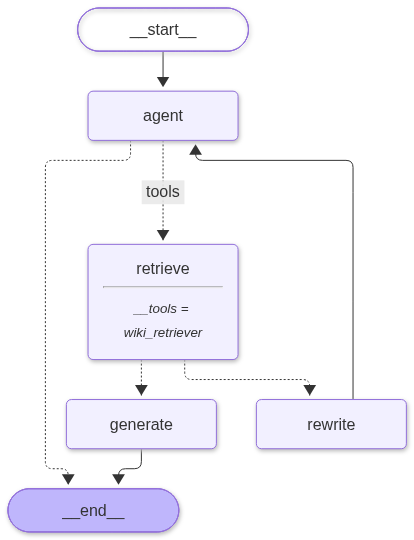

In [9]:
from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

## 6. Ask a question

In [10]:
def ask(prompt: str):
    result = graph.invoke({"messages": [HumanMessage(content=prompt)]})
    for m in result["messages"]:
        m.pretty_print()
    return result["messages"][-1].content

ask("What is retrieval-augmented generation and why does it reduce hallucinations?")

================================ Human Message =================================

What is retrieval-augmented generation and why does it reduce hallucinations?
================================== Ai Message ==================================

**Retrieval‑Augmented Generation (RAG)** is a hybrid architecture that couples a **retriever** (a search or similarity engine) with a **generator** (a large language model, LLM). Instead of asking the LLM to answer a question solely from its internal parameters, the system first pulls relevant external documents—often from a vector‑store or traditional search index—and then feeds those passages to the LLM as context. The LLM “augments” its generation with this retrieved evidence.

---

## 1. How RAG works (step‑by‑step)

| Step | What happens | Typical technology |
|------|--------------|---------------------|
| **1️⃣ Query encoding** | The user’s prompt is turned into a dense vector (or a set of keywords). | Sentence‑transformers, OpenAI embedding

'**Retrieval‑Augmented Generation (RAG)** is a hybrid architecture that couples a **retriever** (a search or similarity engine) with a **generator** (a large language model, LLM). Instead of asking the LLM to answer a question solely from its internal parameters, the system first pulls relevant external documents—often from a vector‑store or traditional search index—and then feeds those passages to the LLM as context. The LLM “augments” its generation with this retrieved evidence.\n\n---\n\n## 1. How RAG works (step‑by‑step)\n\n| Step | What happens | Typical technology |\n|------|--------------|---------------------|\n| **1️⃣ Query encoding** | The user’s prompt is turned into a dense vector (or a set of keywords). | Sentence‑transformers, OpenAI embeddings, etc. |\n| **2️⃣ Retrieval** | The vector is used to look up the *k* most similar documents (or passages) from a knowledge base. | Approximate Nearest‑Neighbor (ANN) index such as FAISS, HNSW, Milvus, Pinecone; or BM25 for lexical 

In [11]:
ask("How do vector databases perform similarity search?")

================================ Human Message =================================

How do vector databases perform similarity search?
================================== Ai Message ==================================

## Overview

Vector databases (sometimes called “vector stores”) are purpose‑built data stores that let you **search for the most similar vectors** to a query vector.  
The core operation is a **nearest‑neighbor (NN) search** in a high‑dimensional space (typically 64‑4096 dimensions) where each vector represents a piece of data (text, image, audio, etc.) that has been encoded by a machine‑learning model.

Below is a step‑by‑step description of how similarity search works inside a vector database, followed by a discussion of the main indexing techniques, distance metrics, and practical trade‑offs.

---

## 1. From Raw Data to Vectors

| Step | What Happens | Why It Matters |
|------|--------------|----------------|
| **Embedding** | A model (e.g., BERT, CLIP, OpenAI’s text‑em

'## Overview\n\nVector databases (sometimes called “vector stores”) are purpose‑built data stores that let you **search for the most similar vectors** to a query vector.  \nThe core operation is a **nearest‑neighbor (NN) search** in a high‑dimensional space (typically 64‑4096 dimensions) where each vector represents a piece of data (text, image, audio, etc.) that has been encoded by a machine‑learning model.\n\nBelow is a step‑by‑step description of how similarity search works inside a vector database, followed by a discussion of the main indexing techniques, distance metrics, and practical trade‑offs.\n\n---\n\n## 1. From Raw Data to Vectors\n\n| Step | What Happens | Why It Matters |\n|------|--------------|----------------|\n| **Embedding** | A model (e.g., BERT, CLIP, OpenAI’s text‑embedding‑ada‑002) converts a raw item (sentence, image, audio clip) into a dense numeric vector **v** ∈ ℝ^d. | The vector captures semantic meaning; similarity in this space ≈ semantic similarity. |\n| 

In [12]:
# Off-topic: the agent should answer directly without retrieval
ask("Hi, who are you?")

================================ Human Message =================================

Hi, who are you?
================================== Ai Message ==================================

Hello! I’m ChatGPT, an AI language model created by OpenAI. I’m here to help answer your questions, brainstorm ideas, explain concepts, or just have a friendly chat—whatever you need. How can I assist you today?


'Hello! I’m ChatGPT, an AI language model created by OpenAI. I’m here to help answer your questions, brainstorm ideas, explain concepts, or just have a friendly chat—whatever you need. How can I assist you today?'